# Task 2: California Housing Price Prediction (OLS vs Ridge vs Lasso)
**Datheon ML & Data Science Internship**

**Goal:** predict median house value, and compare OLS, Ridge (L2) and Lasso (L1) on RMSE, MAE and R2.

**Pipeline:** load + schema check -> EDA -> feature engineering -> train/test split -> imputation + scaling + encoding (inside a pipeline, fitted on train only) -> **multicollinearity check (VIF)** -> models + GridSearchCV -> cross-validation -> residual analysis -> save model.

**Data:** the classic `housing.csv` (20,640 districts; `total_bedrooms` has nulls, `ocean_proximity` is categorical). It is downloaded automatically on first run (or place your copy at `data/housing.csv`). If there is no internet, the notebook falls back to scikit-learn's built-in version.

In [1]:
import os, itertools, warnings
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("models", exist_ok=True); os.makedirs("images", exist_ok=True)
_fig_i = itertools.count(1)
def show_and_save():
    plt.savefig(f"images/fig{next(_fig_i)}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Load data

In [2]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
CSV_PATH = "data/housing.csv"     # local copy; downloaded automatically from DATA_URL on first run

if os.path.exists(CSV_PATH):
    raw = pd.read_csv(CSV_PATH); print("Loaded local file:", CSV_PATH)
else:
    try:
        raw = pd.read_csv(DATA_URL); os.makedirs("data", exist_ok=True); raw.to_csv(CSV_PATH, index=False)
        print("Downloaded housing.csv from GitHub and saved to", CSV_PATH)
    except Exception as e:
        print("Could not download (", type(e).__name__, ") -> falling back to scikit-learn's built-in California Housing")
        sk = fetch_california_housing(as_frame=True).frame
        hh = sk["Population"] / sk["AveOccup"]                      # rebuild the classic housing.csv columns
        raw = pd.DataFrame({"longitude": sk["Longitude"], "latitude": sk["Latitude"], "housing_median_age": sk["HouseAge"],
                            "total_rooms": sk["AveRooms"] * hh, "total_bedrooms": sk["AveBedrms"] * hh,
                            "population": sk["Population"], "households": hh, "median_income": sk["MedInc"],
                            "median_house_value": sk["MedHouseVal"] * 100000})

raw.columns = [c.strip().lower().replace(" ", "_") for c in raw.columns]
TARGET = "median_house_value"
NUM_BASE = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms",
            "population", "households", "median_income"]
missing_cols = [c for c in NUM_BASE + [TARGET] if c not in raw.columns]
assert not missing_cols, f"Columns {missing_cols} not found. Your file has: {list(raw.columns)}. Rename them to match."
CAT_BASE = [c for c in raw.columns if c not in NUM_BASE + [TARGET] and not pd.api.types.is_numeric_dtype(raw[c])]
print("Shape:", raw.shape, "| categorical columns:", CAT_BASE)
print("\nMissing values per column:"); print(raw.isna().sum()[raw.isna().sum() > 0].to_string() or "none")
raw.describe().T.round(2)

Loaded local file: data/housing.csv
Shape: (20640, 10) | categorical columns: ['ocean_proximity']

Missing values per column:
total_bedrooms    207


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


## 2. Exploratory analysis

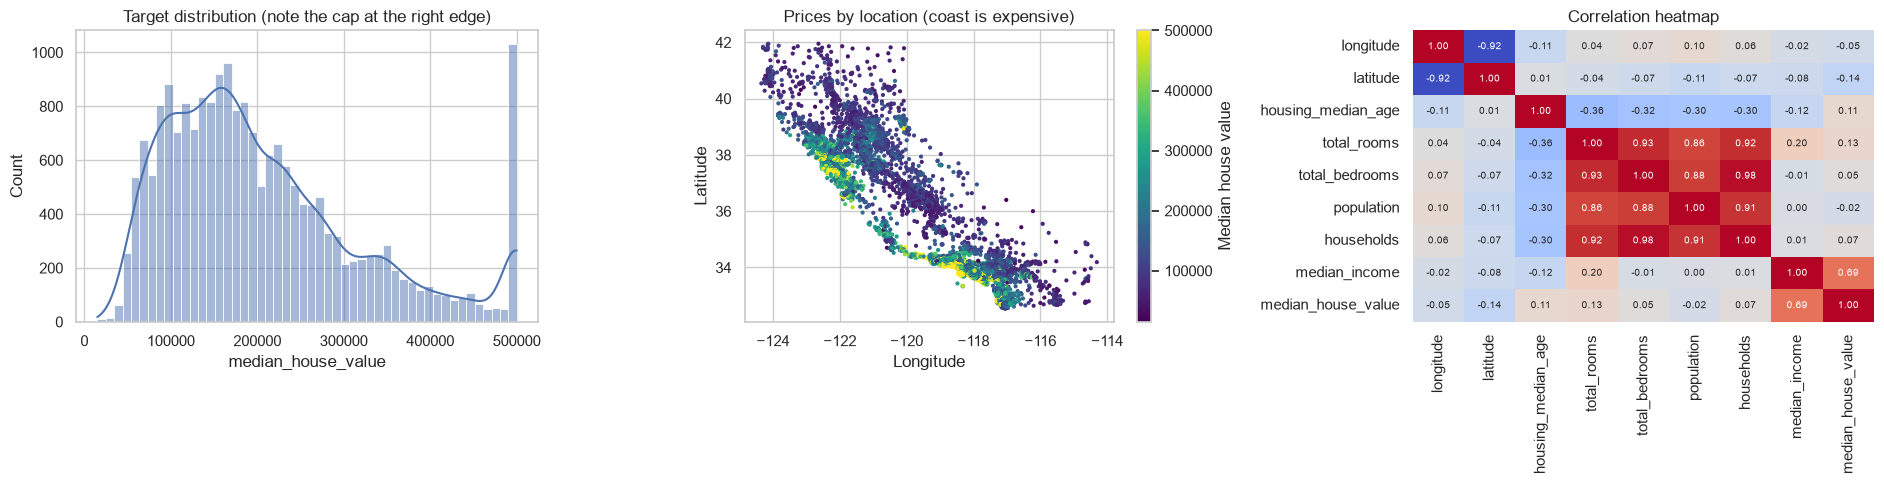

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sns.histplot(raw[TARGET], bins=50, kde=True, ax=ax[0]); ax[0].set_title("Target distribution (note the cap at the right edge)")
sc = ax[1].scatter(raw["longitude"], raw["latitude"], c=raw[TARGET], s=4, cmap="viridis")
plt.colorbar(sc, ax=ax[1], label="Median house value"); ax[1].set_title("Prices by location (coast is expensive)")
ax[1].set_xlabel("Longitude"); ax[1].set_ylabel("Latitude")
sns.heatmap(raw[NUM_BASE + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[2], cbar=False, annot_kws={"size": 7})
ax[2].set_title("Correlation heatmap")
plt.tight_layout(); show_and_save()

## 3. Feature engineering
Per-household ratios and **interaction features** (income x rooms, income x age). Row-wise only, so nothing is learned from the test set.
The target is modelled in units of **$100k** so that Ridge/Lasso alphas are on a sensible scale.

In [4]:
def engineer(d):
    d = d.copy()
    d["rooms_per_household"] = d["total_rooms"] / d["households"]
    d["bedrooms_ratio"] = d["total_bedrooms"] / d["total_rooms"]
    d["population_per_household"] = d["population"] / d["households"]
    d["income_x_rooms"] = d["median_income"] * d["rooms_per_household"]
    d["income_x_age"] = d["median_income"] * d["housing_median_age"]
    return d.replace([np.inf, -np.inf], np.nan)

ENG = ["rooms_per_household", "bedrooms_ratio", "population_per_household", "income_x_rooms", "income_x_age"]
NUM = NUM_BASE + ENG
X = engineer(raw[NUM_BASE + CAT_BASE]); y = raw[TARGET] / 100000
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# winsorise extreme ratios using TRAIN quantiles only
caps = X_train[["rooms_per_household", "population_per_household"]].quantile(0.99)
for c, cap in caps.items():
    X_train[c] = X_train[c].clip(upper=cap); X_test[c] = X_test[c].clip(upper=cap)
print(X_train.shape, X_test.shape)

(16512, 14) (4128, 14)


## 4. Preprocessing (imputation, scaling, encoding), all inside the pipeline
- **Missing values:** median imputation (`SimpleImputer`), fitted on the training fold only.
- **Continuous variables:** `StandardScaler`.
- **Categorical attributes** (e.g. `ocean_proximity`): one-hot encoding (first level dropped to avoid the dummy-variable trap).

In [5]:
def make_pre(num_cols):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    tx = [("num", num, num_cols)]
    if CAT_BASE:
        tx.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                    ("oh", OneHotEncoder(drop="first", handle_unknown="ignore"))]), CAT_BASE))
    return ColumnTransformer(tx)

def make_pipe(model, num_cols=None):
    return Pipeline([("pre", make_pre(num_cols or NUM)), ("m", model)])

print("Missing values in TRAIN features after engineering:", int(X_train[NUM + CAT_BASE].isna().sum().sum()))

Missing values in TRAIN features after engineering: 0


## 5. Multicollinearity: measure it (VIF) and handle it
`total_rooms`, `total_bedrooms`, `population`, `households` move together, and the engineered features add more overlap.
**VIF > 10** signals serious multicollinearity, which makes plain OLS coefficients unstable.
Two ways to handle it here: (a) **drop high-VIF features** (VIF-reduced OLS), (b) **regularise** (Ridge / Lasso).

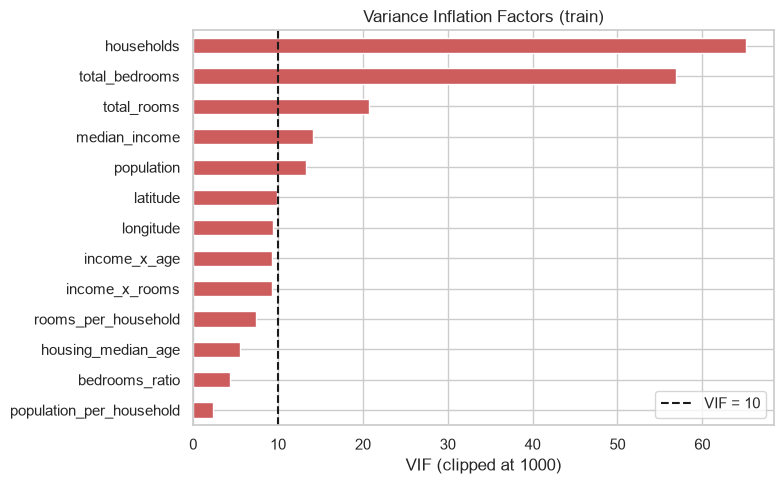

Features with VIF > 10: ['households', 'total_bedrooms', 'total_rooms', 'median_income', 'population']
Dropped for the VIF-reduced model: ['total_bedrooms', 'households', 'median_income']
Kept: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'population', 'rooms_per_household', 'bedrooms_ratio', 'population_per_household', 'income_x_rooms', 'income_x_age']


In [6]:
def vif_table(Xn):
    out = {}
    for c in Xn.columns:
        others = Xn.drop(columns=c)
        r2 = LinearRegression().fit(others, Xn[c]).score(others, Xn[c])
        out[c] = 1 / (1 - r2) if r2 < 0.999999 else np.inf
    return pd.Series(out).sort_values(ascending=False)

def reduce_vif(Xn, thresh=10, protect=()):
    cols = list(Xn.columns)
    while len(cols) > 2:
        v = vif_table(Xn[cols]); cand = v[~v.index.isin(protect)]
        if cand.iloc[0] <= thresh: break
        cols.remove(cand.index[0])
    return cols

Xn = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_train[NUM]), columns=NUM)
vif = vif_table(Xn)
plt.figure(figsize=(8, 5)); vif.clip(upper=1000).iloc[::-1].plot(kind="barh", color="indianred")
plt.axvline(10, color="k", ls="--", label="VIF = 10"); plt.xlabel("VIF (clipped at 1000)"); plt.legend(); plt.title("Variance Inflation Factors (train)")
plt.tight_layout(); show_and_save()

VIF_KEEP = reduce_vif(Xn, thresh=10, protect=("latitude", "longitude"))   # keep location, it carries the signal
print("Features with VIF > 10:", list(vif[vif > 10].index))
print("Dropped for the VIF-reduced model:", [c for c in NUM if c not in VIF_KEEP])
print("Kept:", VIF_KEEP)

## 6. Models: OLS vs Ridge vs Lasso (GridSearchCV over alpha)

In [7]:
alphas = np.logspace(-4, 1, 11)
cv5 = KFold(5, shuffle=True, random_state=42)
searches = {
    "OLS (all features)": make_pipe(LinearRegression()),
    "OLS (VIF-reduced)": make_pipe(LinearRegression(), VIF_KEEP),
    "Ridge (L2)": GridSearchCV(make_pipe(Ridge()), {"m__alpha": alphas}, cv=cv5, scoring="neg_root_mean_squared_error"),
    "Lasso (L1)": GridSearchCV(make_pipe(Lasso(max_iter=50000)), {"m__alpha": alphas}, cv=cv5, scoring="neg_root_mean_squared_error"),
}
rows, preds = [], {}
for name, est in searches.items():
    est.fit(X_train, y_train); p = est.predict(X_test); preds[name] = p
    rmse = np.sqrt(mean_squared_error(y_test, p))
    rows.append({"Model": name, "RMSE ($)": rmse * 100000, "MAE ($)": mean_absolute_error(y_test, p) * 100000,
                 "R2": r2_score(y_test, p), "Best alpha": round(est.best_params_["m__alpha"], 4) if hasattr(est, "best_params_") else "-"})
res = pd.DataFrame(rows).round(4)
res

,Model,RMSE ($),MAE ($),R2,Best alpha
0,OLS (all features),66953.0638,48609.3139,0.6579,-
1,OLS (VIF-reduced),71518.5849,50107.7947,0.6097,-
2,Ridge (L2),66968.1333,48618.2677,0.6578,3.1623
3,Lasso (L1),67002.2667,48574.7524,0.6574,0.001


In [8]:
# 5-fold cross-validation on the training set: more reliable than one split
cv_rows = []
for name, est in searches.items():
    model = est.best_estimator_ if hasattr(est, "best_estimator_") else est
    s = -cross_val_score(model, X_train, y_train, cv=cv5, scoring="neg_root_mean_squared_error") * 100000
    cv_rows.append({"Model": name, "CV RMSE ($) mean": s.mean(), "CV RMSE ($) std": s.std()})
cv_res = pd.DataFrame(cv_rows).round(1)
best_name = cv_res.sort_values("CV RMSE ($) mean").iloc[0]["Model"]
print("Best model by cross-validation:", best_name)
cv_res

Best model by cross-validation: Lasso (L1)


,Model,CV RMSE ($) mean,CV RMSE ($) std
0,OLS (all features),65715.6,1373.2
1,OLS (VIF-reduced),68404.4,1483.9
2,Ridge (L2),65703.5,1352.5
3,Lasso (L1),65701.9,1372.7


## 7. Predicted vs actual and residual distribution

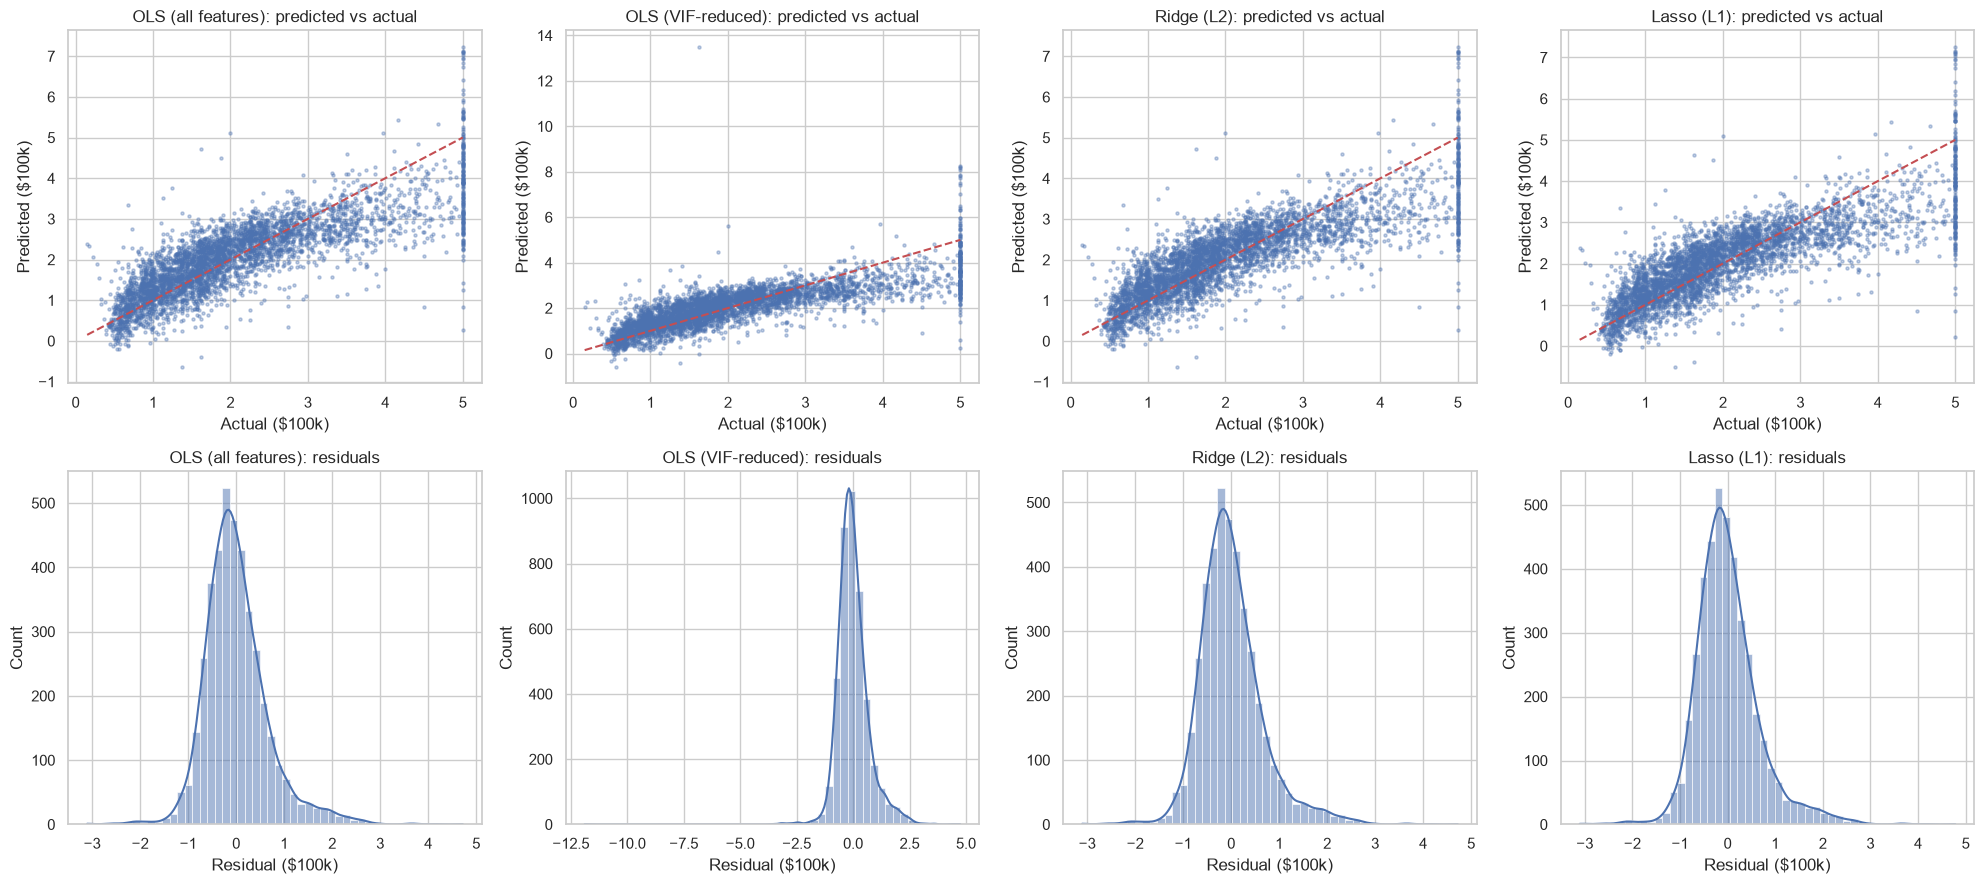

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for i, (name, p) in enumerate(preds.items()):
    axes[0, i].scatter(y_test, p, s=5, alpha=0.35)
    lim = [y_test.min(), y_test.max()]; axes[0, i].plot(lim, lim, "r--")
    axes[0, i].set_title(f"{name}: predicted vs actual"); axes[0, i].set_xlabel("Actual ($100k)"); axes[0, i].set_ylabel("Predicted ($100k)")
    sns.histplot(y_test - p, kde=True, ax=axes[1, i], bins=50)
    axes[1, i].set_title(f"{name}: residuals"); axes[1, i].set_xlabel("Residual ($100k)")
plt.tight_layout(); show_and_save()

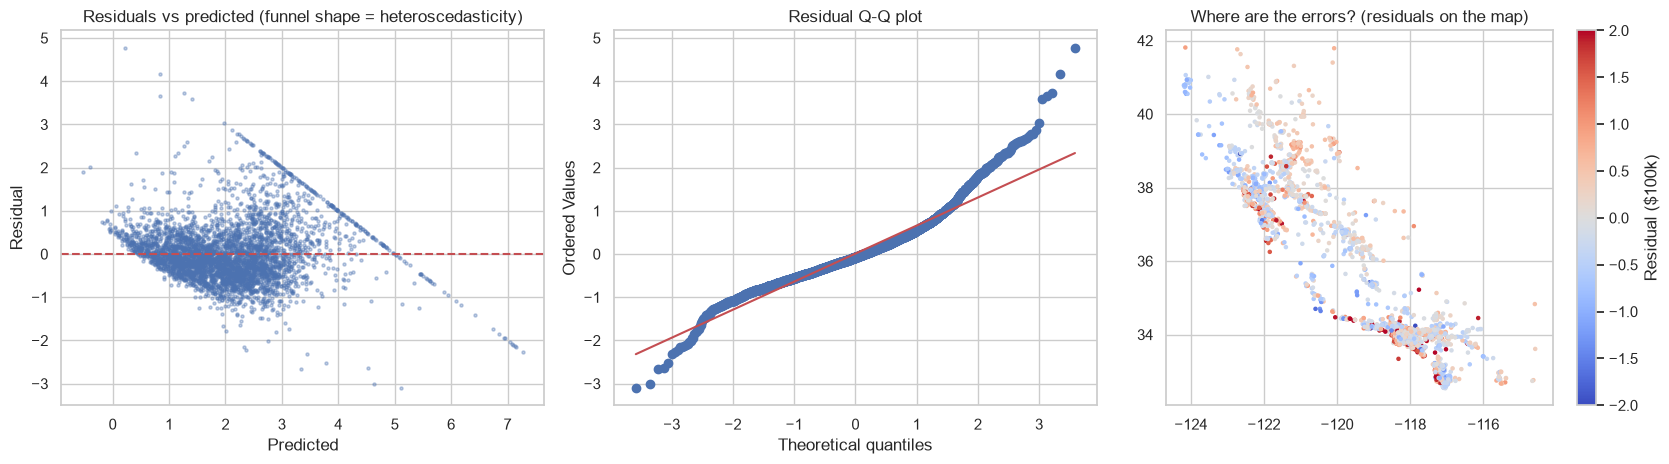

In [10]:
best_est = searches[best_name]; bp = preds[best_name]; resid = y_test - bp
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].scatter(bp, resid, s=5, alpha=0.35); ax[0].axhline(0, color="r", ls="--")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual"); ax[0].set_title("Residuals vs predicted (funnel shape = heteroscedasticity)")
stats.probplot(resid, dist="norm", plot=ax[1]); ax[1].set_title("Residual Q-Q plot")
sc = ax[2].scatter(X_test["longitude"], X_test["latitude"], c=resid, s=5, cmap="coolwarm", vmin=-2, vmax=2)
plt.colorbar(sc, ax=ax[2], label="Residual ($100k)"); ax[2].set_title("Where are the errors? (residuals on the map)")
plt.tight_layout(); show_and_save()

## 8. Which features matter? Ridge vs Lasso coefficients

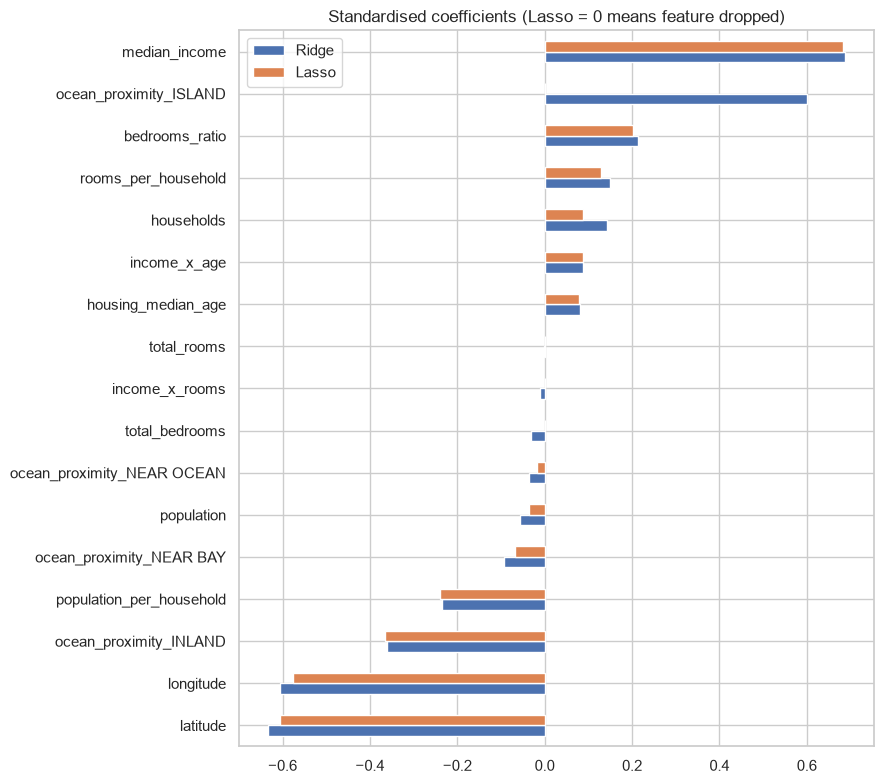

Features Lasso dropped: ['total_rooms', 'total_bedrooms', 'income_x_rooms', 'ocean_proximity_ISLAND']


In [11]:
names = searches["Ridge (L2)"].best_estimator_.named_steps["pre"].get_feature_names_out()
coef = pd.DataFrame({"Ridge": searches["Ridge (L2)"].best_estimator_.named_steps["m"].coef_,
                     "Lasso": searches["Lasso (L1)"].best_estimator_.named_steps["m"].coef_}, index=[n.split("__", 1)[-1] for n in names])
coef.sort_values("Ridge").plot(kind="barh", figsize=(9, 8), title="Standardised coefficients (Lasso = 0 means feature dropped)")
plt.tight_layout(); show_and_save()
print("Features Lasso dropped:", list(coef.index[coef["Lasso"] == 0]) or "none")

## 9. Where does the best model struggle? (error by price range)

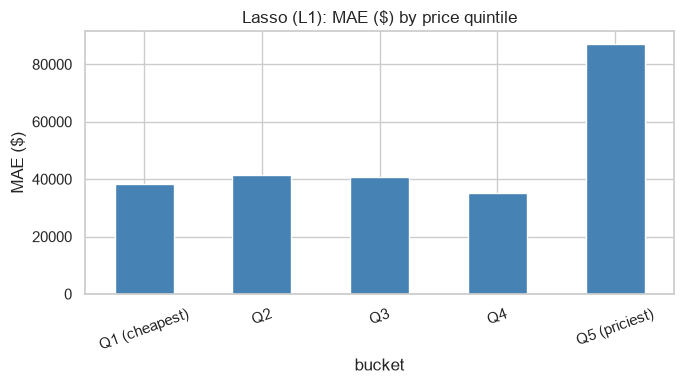

bucket
Q1 (cheapest)    38144.0
Q2               41418.0
Q3               40907.0
Q4               35258.0
Q5 (priciest)    87120.0
Name: abs_err, dtype: float64

In [12]:
err = pd.DataFrame({"actual": y_test, "abs_err": resid.abs() * 100000})
err["bucket"] = pd.qcut(err["actual"], 5, labels=["Q1 (cheapest)", "Q2", "Q3", "Q4", "Q5 (priciest)"])
bucket = err.groupby("bucket", observed=True)["abs_err"].mean()
bucket.plot(kind="bar", color="steelblue", figsize=(7, 4), title=f"{best_name}: MAE ($) by price quintile")
plt.ylabel("MAE ($)"); plt.xticks(rotation=20); plt.tight_layout(); show_and_save()
bucket.round(0)

## 10. Conclusion (auto-generated from your results below; edit freely)

In [13]:
ranges = {c: (float(raw[c].quantile(0.01)), float(raw[c].quantile(0.99)), float(raw[c].median())) for c in NUM_BASE}
joblib.dump({"model": best_est, "name": best_name, "num_base": NUM_BASE, "cat_base": CAT_BASE, "ranges": ranges,
             "cat_options": {c: sorted(raw[c].dropna().unique().tolist()) for c in CAT_BASE},
             "price_percentiles": [float(np.percentile(y, q)) for q in range(0, 101)],
             "rmse_usd": float(res.set_index("Model").loc[best_name, "RMSE ($)"]), "r2": float(res.set_index("Model").loc[best_name, "R2"])},
            "models/housing_model.joblib")
with open("RESULTS.md", "w", encoding="utf-8") as f:
    f.write("## Test-set results\n\n```\n" + res.to_string(index=False) + "\n```\n\n")
    f.write("## 5-fold CV RMSE (training set)\n\n```\n" + cv_res.to_string(index=False) + "\n```\n\n")
    f.write(f"Best model (by CV): {best_name}\nVIF > 10 features: {list(vif[vif > 10].index)}\nDropped in VIF-reduced model: {[c for c in NUM if c not in VIF_KEEP]}\n")
print(open("RESULTS.md", encoding="utf-8").read())

# ---- auto-generated conclusion + results.json (used by finalize.py for README and LinkedIn post) ----
import json
t = res.set_index("Model"); c = cv_res.set_index("Model")
best_cv = c.loc[best_name, "CV RMSE ($) mean"]; ols_cv = c.loc["OLS (all features)", "CV RMSE ($) mean"]; red_cv = c.loc["OLS (VIF-reduced)", "CV RMSE ($) mean"]
gain = (ols_cv - best_cv) / ols_cv * 100
vif_high = list(vif[vif > 10].index)
lasso_dropped = list(coef.index[coef["Lasso"] == 0])
top3 = list(coef["Ridge"].abs().sort_values(ascending=False).head(3).index)
worst_b, best_b = bucket.idxmax(), bucket.idxmin()
lines = [f"- **Best model:** {best_name} (lowest 5-fold CV RMSE, ${best_cv:,.0f}). On the held-out test set: RMSE ${t.loc[best_name, 'RMSE ($)']:,.0f}, MAE ${t.loc[best_name, 'MAE ($)']:,.0f}, R2 {t.loc[best_name, 'R2']:.3f}."]
if best_name == "OLS (all features)":
    lines.append(f"- **Regularisation:** plain OLS was already best on CV (${ols_cv:,.0f}); Ridge and Lasso did not improve on it here.")
else:
    lines.append(f"- **Regularisation / multicollinearity:** {best_name} lowered CV RMSE from ${ols_cv:,.0f} (plain OLS) to ${best_cv:,.0f} ({gain:.1f}% lower{', a marginal gain' if gain < 0.5 else ''}).")
if vif_high:
    shown = ", ".join(vif_high[:6]) + ("..." if len(vif_high) > 6 else "")
    rel = (ols_cv - red_cv) / ols_cv * 100
    if abs(rel) < 0.5:
        verdict = "a negligible difference, so these features are redundant but harmless once the model is regularised."
    elif rel > 0:
        verdict = "so removing them helped."
    else:
        verdict = "so they still carried useful signal; regularisation is the gentler fix."
    lines.append(f"- **Multicollinearity:** {len(vif_high)} features had VIF > 10 ({shown}). OLS on the VIF-reduced set had CV RMSE ${red_cv:,.0f} vs ${ols_cv:,.0f} with all features, {verdict}")
else:
    lines.append("- **Multicollinearity:** no feature exceeded VIF 10.")
lines.append("- **Lasso feature selection:** " + (f"dropped {', '.join(lasso_dropped)}." if lasso_dropped else "kept every feature (no coefficient shrunk to zero)."))
lines.append(f"- **Strongest drivers (largest standardised Ridge coefficients):** {', '.join(top3)}.")
lines.append(f"- **Where it struggles:** largest errors in the {worst_b} price range (MAE ${bucket[worst_b]:,.0f}) vs {best_b} (MAE ${bucket[best_b]:,.0f}).")
lines.append("- **Next step:** try non-linear models (Random Forest / Gradient Boosting) and location clustering, since linear models cannot capture non-linear effects such as location.")
conclusion = "\n".join(lines)
json.dump({"test": res.to_dict("records"), "cv": cv_res.to_dict("records"), "best": best_name, "n_rows": int(len(raw)),
           "vif_high": vif_high, "lasso_dropped": lasso_dropped, "top_features": top3, "conclusion": conclusion},
          open("results.json", "w", encoding="utf-8"), indent=1, default=float)
try:
    from IPython.display import Markdown, display
    display(Markdown("### Auto-generated conclusion\n\n" + conclusion))
except Exception:
    print(conclusion)

## Test-set results

```
             Model   RMSE ($)    MAE ($)     R2 Best alpha
OLS (all features) 66953.0638 48609.3139 0.6579          -
 OLS (VIF-reduced) 71518.5849 50107.7947 0.6097          -
        Ridge (L2) 66968.1333 48618.2677 0.6578     3.1623
        Lasso (L1) 67002.2667 48574.7524 0.6574      0.001
```

## 5-fold CV RMSE (training set)

```
             Model  CV RMSE ($) mean  CV RMSE ($) std
OLS (all features)           65715.6           1373.2
 OLS (VIF-reduced)           68404.4           1483.9
        Ridge (L2)           65703.5           1352.5
        Lasso (L1)           65701.9           1372.7
```

Best model (by CV): Lasso (L1)
VIF > 10 features: ['households', 'total_bedrooms', 'total_rooms', 'median_income', 'population']
Dropped in VIF-reduced model: ['total_bedrooms', 'households', 'median_income']



### Auto-generated conclusion

- **Best model:** Lasso (L1) (lowest 5-fold CV RMSE, $65,702). On the held-out test set: RMSE $67,002, MAE $48,575, R2 0.657.
- **Regularisation / multicollinearity:** Lasso (L1) lowered CV RMSE from $65,716 (plain OLS) to $65,702 (0.0% lower, a marginal gain).
- **Multicollinearity:** 5 features had VIF > 10 (households, total_bedrooms, total_rooms, median_income, population). OLS on the VIF-reduced set had CV RMSE $68,404 vs $65,716 with all features, so they still carried useful signal; regularisation is the gentler fix.
- **Lasso feature selection:** dropped total_rooms, total_bedrooms, income_x_rooms, ocean_proximity_ISLAND.
- **Strongest drivers (largest standardised Ridge coefficients):** median_income, latitude, longitude.
- **Where it struggles:** largest errors in the Q5 (priciest) price range (MAE $87,120) vs Q4 (MAE $35,258).
- **Next step:** try non-linear models (Random Forest / Gradient Boosting) and location clustering, since linear models cannot capture non-linear effects such as location.